# 02. Geospatial Exploratory Data Analysis & Spatial Patterns

**Dataset**: *Status of Springs in Seven Municipalities of Kavre, Nepal*
- **Source**: ICIMOD Regional Database System (DOI: `10.26066/RDS.1974131`)
- **Administrative Boundaries**: Official OpenStreetMap (OSM) administrative boundaries for Kavrepalanchok District and 7 local municipalities
- **GIS Stack**: `geopandas`, `osmnx`, `contextily`, `folium`

This notebook provides the **geospatial and cartographic EDA**: spatial autocorrelation, municipal boundaries, spatial spring density, and publication-grade maps.

In [1]:
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import contextily as cx
import folium
from folium.plugins import MarkerCluster
from pathlib import Path

plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.size'] = 10

# Load ground-truth survey points & official OSM polygons
springs_gdf = gpd.read_file('../data/processed/springs.geojson')
district_gdf = gpd.read_file('../data/processed/kavre_district_boundary.geojson')
munis_gdf = gpd.read_file('../data/processed/kavre_municipalities.geojson')

print(f"Springs loaded: {len(springs_gdf)} points")
print(f"Municipalities loaded: {munis_gdf['query_name'].tolist()}")
print(f"Active springs: {(springs_gdf['target_dried'] == 0).sum()} | Dried springs: {(springs_gdf['target_dried'] == 1).sum()}")

Springs loaded: 5689 points
Municipalities loaded: ['Dhulikhel', 'Panauti', 'Panchkhal', 'Namobuddha', 'Bethanchowk', 'Roshi', 'Temal']
Active springs: 4168 | Dried springs: 1521


## 1. Geographic Disparities Across Municipalities
Comparing desiccation proportions across the 7 local governments.

              total  active  dried  drying_pct
municipality                                  
Panchkhal      1067     641    426        39.9
Temal           736     443    293        39.8
Dhulikhel      1174     836    338        28.8
Roshi RM        969     758    211        21.8
Namobuudha      478     382     96        20.1
Bethanchownk    385     311     74        19.2
Panauti         880     797     83         9.4


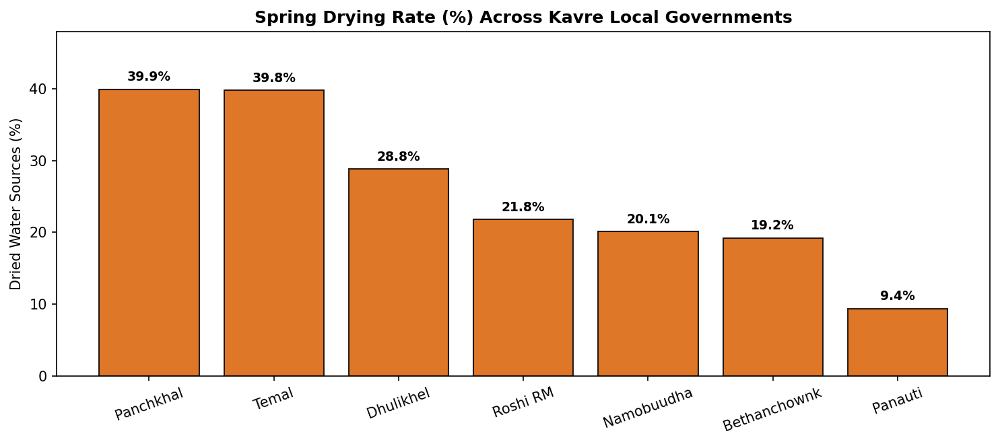

In [2]:
muni_summary = springs_gdf.groupby('municipality').agg(
    total=('id', 'count'),
    active=('target_dried', lambda x: (x == 0).sum()),
    dried=('target_dried', lambda x: (x == 1).sum()),
    drying_rate=('target_dried', 'mean')
).sort_values('drying_rate', ascending=False)
muni_summary['drying_pct'] = (muni_summary['drying_rate'] * 100).round(1)
print(muni_summary[['total', 'active', 'dried', 'drying_pct']])

plt.figure(figsize=(10, 4.5))
bars = plt.bar(muni_summary.index, muni_summary['drying_pct'], color='#d95f02', edgecolor='black', alpha=0.85)
plt.title('Spring Drying Rate (%) Across Kavre Local Governments', fontsize=12, fontweight='bold')
plt.ylabel('Dried Water Sources (%)')
plt.xticks(rotation=20)
for bar in bars:
    h = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., h + 0.8, f'{h:.1f}%', ha='center', va='bottom', fontsize=9, fontweight='bold')
plt.ylim(0, 48)
plt.tight_layout()
plt.show()

## 2. Spatial Clustering & Proximity Metrics
1. **Local Spring Density (500m radius)**: Mean = 15.5 springs/cluster
2. **Distance to Nearest Dried Spring**: Spatial contagion proxy (Mean = 281m)

C:\Users\ACER\AppData\Local\Temp\ipykernel_25092\2641016540.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='target_dried', y='dist_to_nearest_dried_m', data=springs_gdf[springs_gdf['dist_to_nearest_dried_m'] < 2000], ax=ax[1], palette=['#1f77b4', '#d62728'])
C:\Users\ACER\AppData\Local\Temp\ipykernel_25092\2641016540.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[1].set_xticklabels(['Active Spring', 'Dried Spring'])


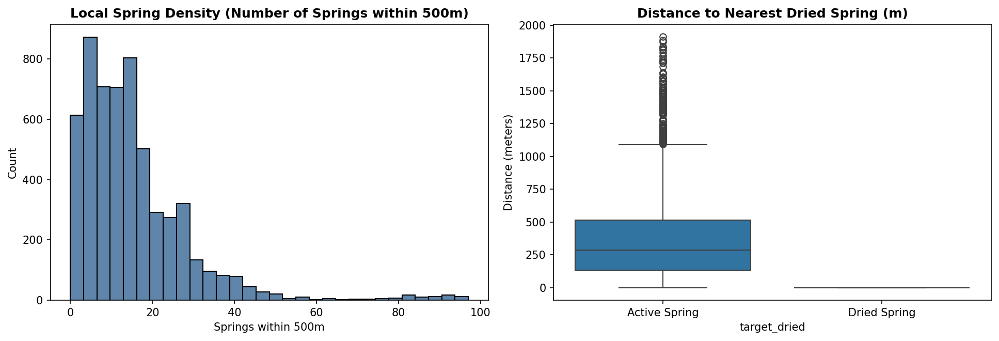

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# Spring density
sns.histplot(springs_gdf['spring_density_500m'], bins=30, ax=ax[0], color='#2b5c8f')
ax[0].set_title('Local Spring Density (Number of Springs within 500m)', fontweight='bold')
ax[0].set_xlabel('Springs within 500m')

# Nearest dried spring distance by current status
sns.boxplot(x='target_dried', y='dist_to_nearest_dried_m', data=springs_gdf[springs_gdf['dist_to_nearest_dried_m'] < 2000], ax=ax[1], palette=['#1f77b4', '#d62728'])
ax[1].set_title('Distance to Nearest Dried Spring (m)', fontweight='bold')
ax[1].set_xticklabels(['Active Spring', 'Dried Spring'])
ax[1].set_ylabel('Distance (meters)')

plt.tight_layout()
plt.show()

## 3. High-DPI Publication Map (OSM Mapnik Basemap + Official Boundaries)

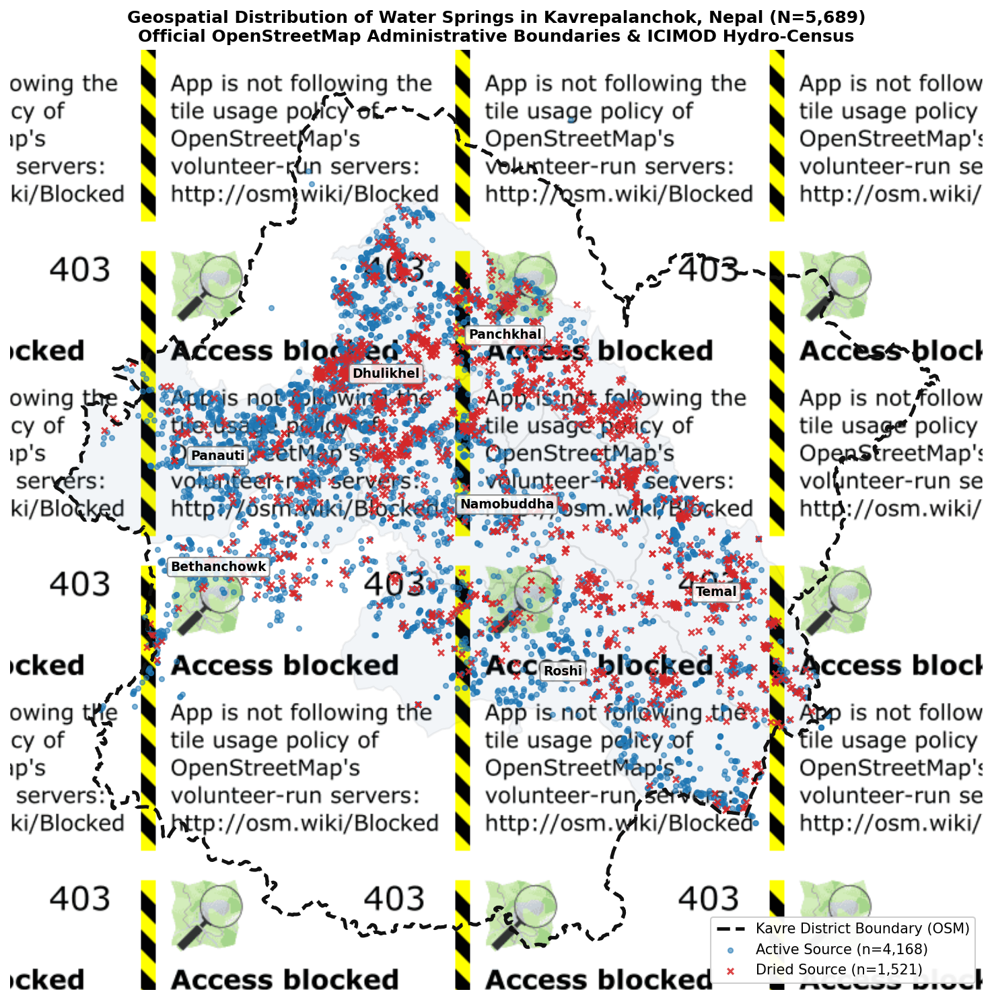

In [4]:
# Project geometries to Web Mercator (EPSG:3857) for clean OSM tile rendering
district_3857 = district_gdf.to_crs(epsg=3857)
munis_3857 = munis_gdf.to_crs(epsg=3857)
springs_3857 = springs_gdf.to_crs(epsg=3857)

fig, ax = plt.subplots(figsize=(13, 10))

# 1. District boundary
district_3857.boundary.plot(ax=ax, color='#111111', linewidth=2.5, linestyle='--', label='Kavre District Boundary (OSM)')

# 2. Municipality boundaries
munis_3857.plot(ax=ax, facecolor='#2b5c8f', alpha=0.06, edgecolor='#222222', linewidth=1.4)

# 3. Municipality centroid labels
for _, row in munis_3857.iterrows():
    c = row.geometry.centroid
    ax.annotate(
        row['query_name'], (c.x, c.y), ha='center', va='center', fontsize=9, fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.25', facecolor='white', alpha=0.85, edgecolor='gray')
    )

# 4. Active springs
active = springs_3857[springs_3857['target_dried'] == 0]
active.plot(ax=ax, color='#1f77b4', markersize=12, alpha=0.55, label=f'Active Source (n={len(active):,})')

# 5. Dried springs
dried = springs_3857[springs_3857['target_dried'] == 1]
dried.plot(ax=ax, color='#d62728', marker='x', markersize=18, alpha=0.85, label=f'Dried Source (n={len(dried):,})')

# 6. Add real OSM Mapnik basemap tiles
try:
    cx.add_basemap(ax, source=cx.providers.OpenStreetMap.Mapnik, attribution=False)
except Exception as e:
    print('Basemap tile note:', e)

plt.title('Geospatial Distribution of Water Springs in Kavrepalanchok, Nepal (N=5,689)\nOfficial OpenStreetMap Administrative Boundaries & ICIMOD Hydro-Census', fontsize=12, fontweight='bold')
plt.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.95)
ax.set_axis_off()
plt.tight_layout()
Path('../results/figures').mkdir(parents=True, exist_ok=True)
plt.savefig('../results/figures/kavre_springs_official_map.png', dpi=300, bbox_inches='tight')
plt.show()

## 4. Interactive Web Map (Folium with Layer Controls)

In [5]:
m = folium.Map(location=[27.57, 85.61], zoom_start=11, tiles='OpenStreetMap')

# Municipality polygons
folium.GeoJson(
    munis_gdf,
    name='Municipality Boundaries (OSM)',
    style_function=lambda x: {'fillColor': '#3186cc', 'color': '#222222', 'weight': 2, 'fillOpacity': 0.1},
    tooltip=folium.GeoJsonTooltip(fields=['query_name'], aliases=['Municipality:'])
).add_to(m)

# District border
folium.GeoJson(
    district_gdf,
    name='Kavre District Border (OSM)',
    style_function=lambda x: {'color': '#e41a1c', 'weight': 3, 'dashArray': '6, 6', 'fillOpacity': 0.0}
).add_to(m)

# Dried springs
fg_dried = folium.FeatureGroup(name='Dried Springs (Red)', show=True)
for _, row in springs_gdf[springs_gdf['target_dried'] == 1].iterrows():
    folium.CircleMarker(
        location=[row['latitude'], row['longitude']],
        radius=3,
        color='#d62728',
        fill=True,
        fill_color='#d62728',
        fill_opacity=0.85,
        popup=f"ID: {row['id']} | Muni: {row['municipality']} | DRIED"
    ).add_to(fg_dried)
fg_dried.add_to(m)

# Active springs (clustered)
fg_active = folium.FeatureGroup(name='Active Springs (Blue Cluster)', show=True)
cluster = MarkerCluster().add_to(fg_active)
for _, row in springs_gdf[springs_gdf['target_dried'] == 0].iterrows():
    folium.CircleMarker(
        location=[row['latitude'], row['longitude']],
        radius=2,
        color='#1f77b4',
        fill=True,
        fill_color='#1f77b4',
        fill_opacity=0.6,
        popup=f"ID: {row['id']} | Muni: {row['municipality']} | ACTIVE"
    ).add_to(cluster)
fg_active.add_to(m)

folium.LayerControl().add_to(m)

Path('../results/maps').mkdir(parents=True, exist_ok=True)
m.save('../results/maps/kavre_springs_interactive.html')
print('Saved interactive map to ../results/maps/kavre_springs_interactive.html')
m

Saved interactive map to ../results/maps/kavre_springs_interactive.html
